In [1]:
import anndata as ad
import pandas as pd
import os

# sparsity_dir = '/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/split/sparsity_comparison/'
sparsity_dir = '/work/magroup/skrieger/Syndri/data/datasets/brain_merfish/results/split/sparsity_comparison/'
files = sorted([f for f in os.listdir(sparsity_dir)])
df = pd.concat([pd.read_csv(os.path.join(sparsity_dir, f)) for f in files],axis=0)
print(df.head().to_string())

                                                                                                         spatial_file input_layer             result_layer                                                                                                         profile_cache                  label_source  n_excluded_cells                cell_scope          cell_type           stage  n_cells  n_genes  n_entries  n_nonzero    n_zero  zero_fraction  mean_profile_zero_fraction
0  /work/magroup/skrieger/Syndri/data/datasets/brain_merfish/results/final/st_integrated_slice-Zhuang-ABCA-4.001.h5ad           X  split_purified_counts_X  /home/jwinchel/Syndri/data/cache/rctd_profiles/f73b8dbfc32af9e35827748beecb34244b7ac16ae7bae3ec1dd6f8606afe4c22.h5ad  original_rctd_weights_argmax               347  merged_h5ad_valid_labels      01 IT-ET Glut   scrna_profile        1     1122       1122       1107        15       0.013369                    0.013369
1  /work/magroup/skrieger/Syndri/data/datasets/bra

In [40]:
df[df['stage']=='scrna_profile']['cell_type'].unique()

array(['capillary endothelial cell', 'fibroblast of lung', 'macrophage',
       'malignant cell', 'plasma cell'], dtype=object)

<Axes: xlabel='cell_type', ylabel='mean_profile_zero_fraction'>

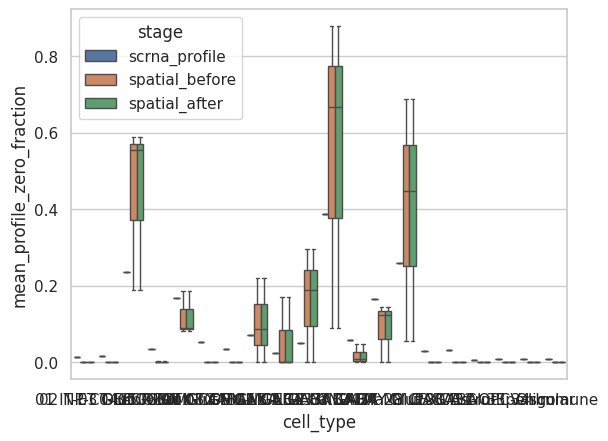

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=df,x='cell_type',y='mean_profile_zero_fraction',hue='stage')

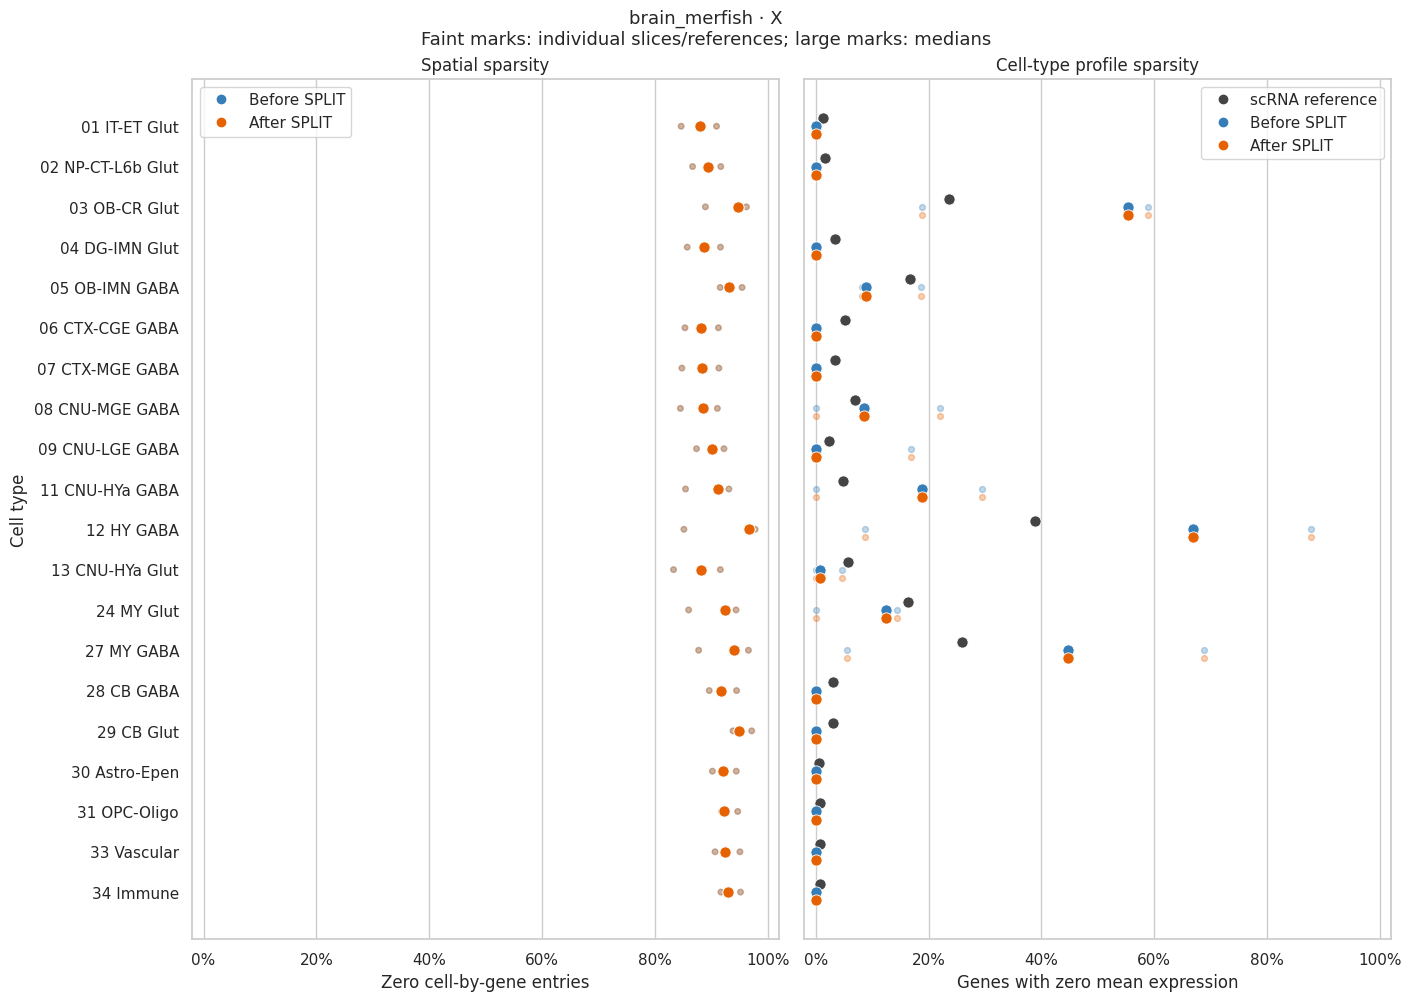

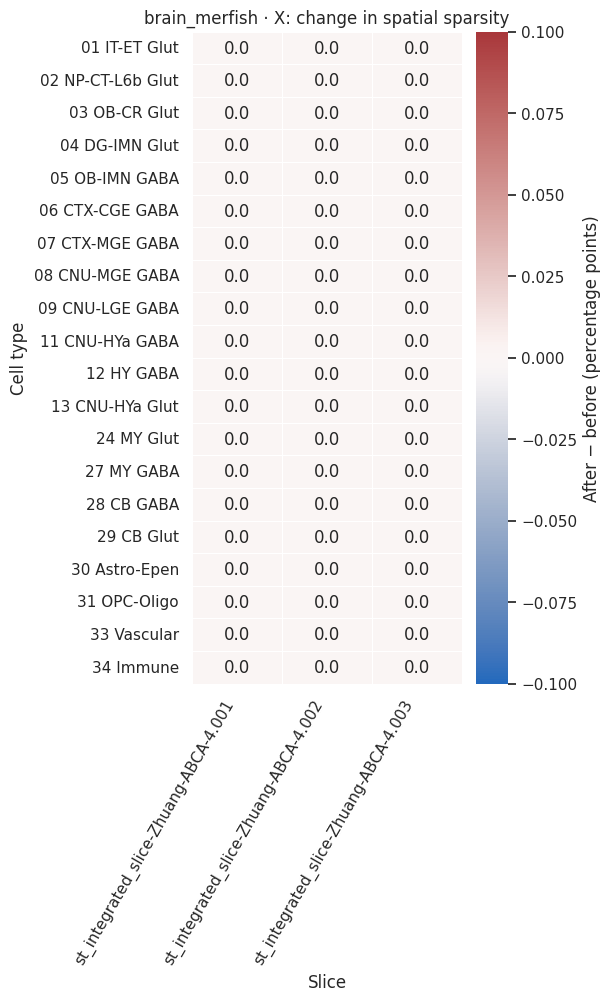

In [51]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import seaborn as sns

plot_df = df.copy()


def dataset_from_path(path):
    parts = Path(path).parts
    if "datasets" in parts:
        return parts[parts.index("datasets") + 1]
    return "dataset"


plot_df["dataset"] = plot_df["spatial_file"].map(dataset_from_path)
plot_df["slice"] = plot_df["spatial_file"].map(lambda p: Path(p).stem)

# Reject duplicated observations rather than silently averaging repeated imports.
identity = ["spatial_file", "input_layer", "cell_type", "stage"]
if plot_df.duplicated(identity).any():
    raise ValueError(
        "Duplicate file/layer/cell-type/stage rows found. "
        "Select one result set or remove duplicated imports first."
    )

colors = {
    "scrna_profile": "#444444",
    "spatial_before": "#377eb8",
    "spatial_after": "#e66101",
}
stage_labels = {
    "scrna_profile": "scRNA reference",
    "spatial_before": "Before SPLIT",
    "spatial_after": "After SPLIT",
}

sns.set_theme(style="whitegrid", context="notebook")

for (dataset, layer), group in plot_df.groupby(
    ["dataset", "input_layer"], sort=True
):
    # One row per slice/cell type, preserving before/after pairing.
    spatial = (
        group[group["stage"].isin(["spatial_before", "spatial_after"])]
        .pivot(
            index=["spatial_file", "cell_type"],
            columns="stage",
            values="zero_fraction",
        )
        .reindex(columns=["spatial_before", "spatial_after"])
        .dropna()
    )

    if spatial.empty:
        continue

    # Order cell types by median increase in spatial sparsity.
    change = spatial["spatial_after"] - spatial["spatial_before"]
    order = (
        change.groupby(level="cell_type")
        .median()
        .sort_values(ascending=False)
        .index.tolist()
    )
    y = np.arange(len(order))
    height = max(4, 0.42 * len(order) + 1.5)

    fig, axes = plt.subplots(
        1, 2, figsize=(14, height), sharey=True,
        constrained_layout=True,
    )

    # ---------------------------------------------------------------
    # Panel 1: fraction of zero cell-by-gene entries.
    # ---------------------------------------------------------------
    ax = axes[0]

    for yi, cell_type in enumerate(order):
        pairs = spatial.xs(cell_type, level="cell_type")

        # Keep each slice visible.
        for before, after in pairs[
            ["spatial_before", "spatial_after"]
        ].itertuples(index=False, name=None):
            ax.plot(
                [before, after], [yi, yi],
                color="0.6", alpha=0.25, linewidth=1, zorder=1,
            )
            ax.scatter(
                [before, after], [yi, yi],
                c=[colors["spatial_before"], colors["spatial_after"]],
                s=16, alpha=0.3, zorder=2,
            )

        medians = pairs.median()
        ax.plot(
            [medians["spatial_before"], medians["spatial_after"]],
            [yi, yi], color="0.3", linewidth=2, zorder=3,
        )
        for stage in ["spatial_before", "spatial_after"]:
            ax.scatter(
                medians[stage], yi, color=colors[stage],
                s=65, edgecolor="white", linewidth=0.6, zorder=4,
            )

    ax.set_title("Spatial sparsity")
    ax.set_xlabel("Zero cell-by-gene entries")
    ax.set_yticks(y)
    ax.set_yticklabels(order)
    ax.set_ylabel("Cell type")
    ax.legend(handles=[
        Line2D(
            [], [], marker="o", linestyle="none",
            color=colors[s], label=stage_labels[s],
        )
        for s in ["spatial_before", "spatial_after"]
    ], loc="best")

    # ---------------------------------------------------------------
    # Panel 2: zero genes in each cell-type mean profile.
    # Use mean_profile_zero_fraction for ALL three stages.
    # ---------------------------------------------------------------
    ax = axes[1]
    offsets = {
        "scrna_profile": -0.2,
        "spatial_before": 0,
        "spatial_after": 0.2,
    }

    for stage, offset in offsets.items():
        values = group[group["stage"].eq(stage)]

        # A shared cached reference is repeated for each spatial file.
        # Display each distinct reference profile only once per cell type.
        if stage == "scrna_profile":
            values = values.drop_duplicates(["profile_cache", "cell_type"])

        for yi, cell_type in enumerate(order):
            fractions = values.loc[
                values["cell_type"].eq(cell_type),
                "mean_profile_zero_fraction",
            ].dropna()

            if fractions.empty:
                continue

            ax.scatter(
                fractions,
                np.full(len(fractions), yi + offset),
                color=colors[stage], s=18, alpha=0.3, zorder=2,
            )
            ax.scatter(
                fractions.median(), yi + offset,
                color=colors[stage], s=65,
                edgecolor="white", linewidth=0.6, zorder=3,
            )

    ax.set_title("Cell-type profile sparsity")
    ax.set_xlabel("Genes with zero mean expression")
    ax.legend(handles=[
        Line2D(
            [], [], marker="o", linestyle="none",
            color=colors[s], label=stage_labels[s],
        )
        for s in offsets
    ], loc="best")

    for ax in axes:
        ax.set_xlim(-0.02, 1.02)
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.grid(axis="y", visible=False)

    axes[0].invert_yaxis()
    fig.suptitle(
        f"{dataset} · {layer}\n"
        "Faint marks: individual slices/references; large marks: medians",
        fontsize=13,
    )
    # fig.savefig(f"{dataset}_{layer}_sparsity.pdf", bbox_inches="tight")
    plt.show()

    # ---------------------------------------------------------------
    # Heatmap: paired change in spatial sparsity, percentage points.
    # ---------------------------------------------------------------
    heatmap = (
        (100 * change)
        .rename("change_pp")
        .reset_index()
        .pivot(
            index="cell_type",
            columns="spatial_file",
            values="change_pp",
        )
        .reindex(order)
    )
    heatmap.columns = [Path(p).stem for p in heatmap.columns]

    limit = max(float(np.nanmax(np.abs(heatmap.to_numpy()))), 0.1)

    fig, ax = plt.subplots(
        figsize=(max(6, 0.75 * heatmap.shape[1]), height),
        constrained_layout=True,
    )
    sns.heatmap(
        heatmap,
        ax=ax,
        cmap="vlag",
        center=0,
        vmin=-limit,
        vmax=limit,
        mask=heatmap.isna(),
        annot=heatmap.size <= 200,
        fmt=".1f",
        linewidths=0.4,
        cbar_kws={"label": "After − before (percentage points)"},
    )
    ax.set_facecolor("#eeeeee")  # Missing combinations remain visibly distinct.
    ax.set_title(f"{dataset} · {layer}: change in spatial sparsity")
    ax.set_xlabel("Slice")
    ax.set_ylabel("Cell type")
    plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
    # fig.savefig(f"{dataset}_{layer}_sparsity_change.pdf", bbox_inches="tight")
    plt.show()